# MFPCA amb correlació progressiva entre X1 i X2

Autor: Leonel Fernando Nabaza Ruibal

Variant de l'experiment anterior. Ara, en lloc d'una correlació puntual (només al
mateix instant $t$), volem que la correlació entre $X^{(1)}(t_i)$ i $X^{(2)}(t_j)$
**decreixi progressivament** a mesura que $t_i$ i $t_j$ s'allunyen:

$$
\mathrm{corr}\big(X^{(1)}(t_i), X^{(2)}(t_j)\big) = \rho \cdot \kappa(t_i, t_j)
$$

on $\kappa$ és un nucli que val 1 quan $t_i=t_j$ i decau suaument amb la distància
$|t_i-t_j|$ (nucli RBF/gaussià). Volem comprovar si, amb aquesta estructura **suau**
(en lloc de puntual), la MFPCA sí que conserva la correlació en les noves PCs.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.values import DenseValues
from FDApy.preprocessing.dim_reduction.mfpca import MFPCA
from FDApy.preprocessing.dim_reduction.ufpca import UFPCA

np.random.seed(123)


---
# Part 1 — Funcions i generació de les dades

Seguim fent servir una forma mitjana senzilla:

$$
X^{(1)}(t) = \sin(t) + 0.5\,\varepsilon_1(t), \qquad
X^{(2)}(t) = 3\sin(t) + 0.5\,\varepsilon_2(t), \qquad t\in[0,2\pi]
$$

Però ara el soroll $\varepsilon_1(t), \varepsilon_2(t)$ **ja no és independent entre
instants**: cadascun és un procés gaussià suau (nucli RBF amb longitud d'escala
$\ell$), i tots dos comparteixen una part comuna $W(t)$ que els correlaciona:

$$
\varepsilon_1(t) = \sqrt{\rho}\,W(t) + \sqrt{1-\rho}\,W_1(t), \qquad
\varepsilon_2(t) = \sqrt{\rho}\,W(t) + \sqrt{1-\rho}\,W_2(t)
$$

on $W, W_1, W_2$ són processos gaussians independents amb nucli
$\kappa(s,t) = \exp\!\big(-(s-t)^2/2\ell^2\big)$ (variància 1). Amb això s'obté
exactament $\mathrm{corr}(\varepsilon_1(t_i),\varepsilon_2(t_j)) = \rho\,\kappa(t_i,t_j)$:
val $\rho=0.9$ quan $i=j$ i decreix suaument cap a 0 a mesura que $t_i$ i $t_j$
s'allunyen.


In [2]:
n = 200
t = np.linspace(0, 2*np.pi, 100)
argvals = DenseArgvals({'input_dim_0': t})

rho = 0.9
l = 1.2   # longitud d'escala del nucli RBF: a més l, decaiment més lent

diff = t[:, None] - t[None, :]
Kmat = np.exp(-diff**2 / (2*l**2)) + 1e-8*np.eye(len(t))   # + petit jitter numeric
Lk = np.linalg.cholesky(Kmat)

W  = np.random.standard_normal((n, len(t))) @ Lk.T   # part comuna
W1 = np.random.standard_normal((n, len(t))) @ Lk.T   # part pròpia de X1
W2 = np.random.standard_normal((n, len(t))) @ Lk.T   # part pròpia de X2

eps1 = np.sqrt(rho)*W + np.sqrt(1 - rho)*W1
eps2 = np.sqrt(rho)*W + np.sqrt(1 - rho)*W2

X1 = np.sin(t)[None, :]   + 0.5 * eps1
X2 = 3*np.sin(t)[None, :] + 0.5 * eps2


---
# Part 2 — Comprovació de l'estructura de correlació generada

Com abans, calculem $\mathrm{corr}(X^{(1)}(t_i), X^{(2)}(t_j))$ per a tots els parells
$(i,j)$, i ara també com decau en funció de la distància $|t_i-t_j|$.


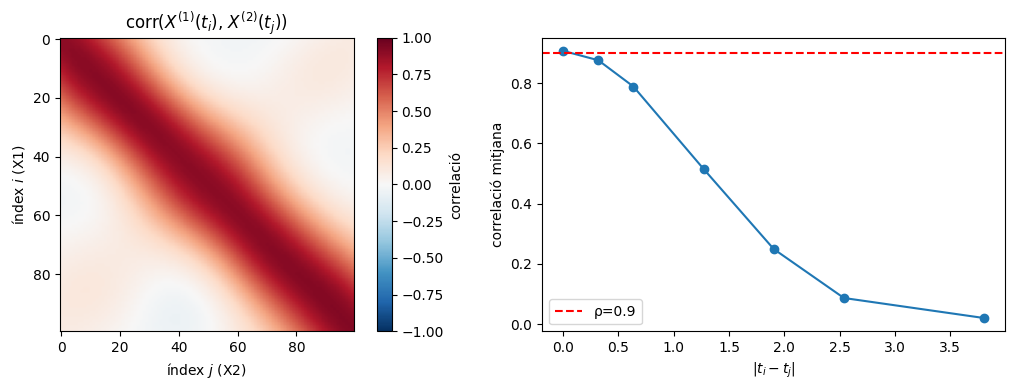

In [3]:
X1c = X1 - X1.mean(axis=0)
X2c = X2 - X2.mean(axis=0)
C = np.corrcoef(X1c.T, X2c.T)[:len(t), len(t):]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

im = axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], label="correlació")
axes[0].set_title("corr($X^{(1)}(t_i)$, $X^{(2)}(t_j)$)")
axes[0].set_xlabel("índex $j$ (X2)")
axes[0].set_ylabel("índex $i$ (X1)")

distancies = [0, 5, 10, 20, 30, 40, 60]
corr_mitjana = [np.mean([C[i, i+d] for i in range(len(t)-d)]) for d in distancies]
axes[1].plot([d*(t[1]-t[0]) for d in distancies], corr_mitjana, "o-")
axes[1].axhline(rho, color="red", linestyle="--", label=f"ρ={rho}")
axes[1].set_xlabel("$|t_i - t_j|$")
axes[1].set_ylabel("correlació mitjana")
axes[1].legend()

plt.tight_layout()
plt.show()


## Construcció dels objectes funcionals

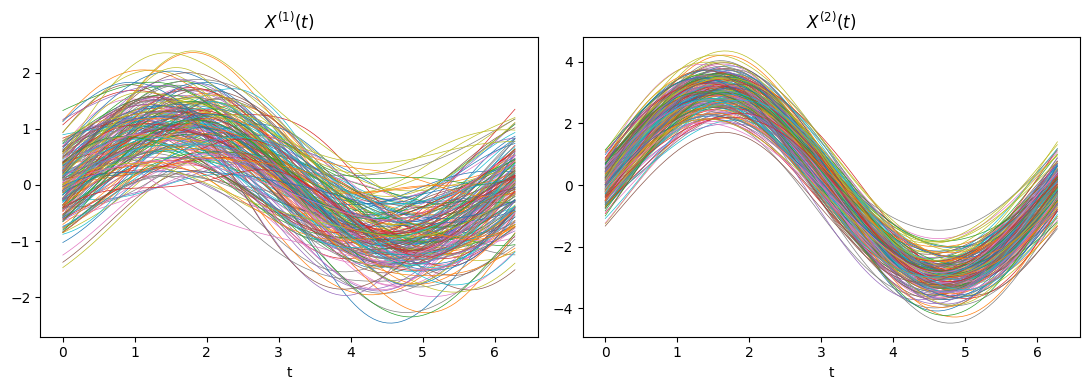

In [4]:
fd1 = DenseFunctionalData(argvals, DenseValues(X1))
fd2 = DenseFunctionalData(argvals, DenseValues(X2))
mData = MultivariateFunctionalData([fd1, fd2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, X1.T, linewidth=0.5)
axes[0].set_title("$X^{(1)}(t)$")
axes[0].set_xlabel("t")
axes[1].plot(t, X2.T, linewidth=0.5)
axes[1].set_title("$X^{(2)}(t)$")
axes[1].set_xlabel("t")
plt.tight_layout()
plt.show()


---
# Part 3 — Ajust de la MFPCA i de la FPCA univariant per separat


In [5]:
K = 5  # nombre de components a estudiar

uniExpansions = [
    {'method': 'UFPCA', 'n_components': 10},
    {'method': 'UFPCA', 'n_components': 10},
]
mfpca = MFPCA(n_components=K, method='covariance', univariate_expansions=uniExpansions)
mfpca.fit(mData)

print("Valors propis MFPCA:", np.round(mfpca.eigenvalues, 4))


Valors propis MFPCA: [1.2947 0.8572 0.6094 0.1917 0.0883]


In [6]:
ufpca1 = UFPCA(n_components=K, method='covariance')
ufpca1.fit(fd1)
scores1 = ufpca1.transform(fd1)

ufpca2 = UFPCA(n_components=K, method='covariance')
ufpca2.fit(fd2)
scores2 = ufpca2.transform(fd2)

print("Valors propis X1:", np.round(ufpca1.eigenvalues, 4))
print("Valors propis X2:", np.round(ufpca2.eigenvalues, 4))


Valors propis X1: [0.6816 0.4276 0.3308 0.1036 0.0477]
Valors propis X2: [0.6861 0.4655 0.3038 0.0979 0.0432]


---
# Part 4 — Es conserva la correlació en les noves PCs?

Igual que abans, comparem $\rho=0.9$ amb la correlació entre els scores de cada
component. El **signe** d'una autofunció no està determinat (pot sortir invertit de
manera independent a X1 i a X2), per això també mostrem el valor absolut.


Correlació original (en el mateix instant, rho): 0.9

  Component 1: 0.8925  (|·| = 0.8925)
  Component 2: -0.9157  (|·| = 0.9157)
  Component 3: 0.9162  (|·| = 0.9162)
  Component 4: -0.9024  (|·| = 0.9024)
  Component 5: 0.9113  (|·| = 0.9113)


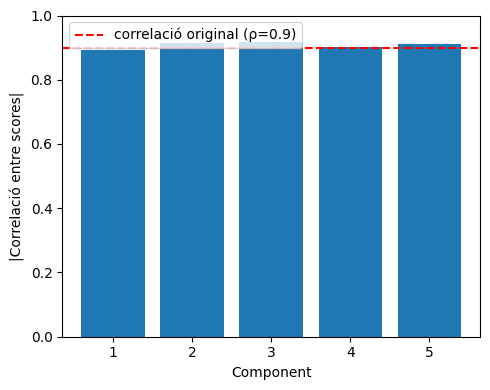

In [7]:
print(f"Correlació original (en el mateix instant, rho): {rho}\n")

corr_scores = []
for k in range(K):
    c = np.corrcoef(scores1[:, k], scores2[:, k])[0, 1]
    corr_scores.append(c)
    print(f"  Component {k+1}: {c:.4f}  (|·| = {abs(c):.4f})")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(range(1, K+1), np.abs(corr_scores))
ax.axhline(rho, color="red", linestyle="--", label=f"correlació original (ρ={rho})")
ax.set_xlabel("Component")
ax.set_ylabel("|Correlació entre scores|")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()


---
# Conclusió

A diferència de l'experiment amb correlació puntual, aquí els **valors propis
decreixen clarament** (hi ha un patró de baixa dimensió real, gràcies a la part
comuna suau $W(t)$) i la correlació entre els scores de cada component es manté
**molt a prop de 0.9** (en valor absolut) a totes les components.

La conclusió és la contrària a l'experiment anterior: quan la correlació entre
$X^{(1)}$ i $X^{(2)}$ prové d'un **patró funcional suau compartit** (i no només de
soroll puntual independent), la MFPCA sí que la captura i la conserva en les seves
components principals — tal com cabria esperar, ja que això és exactament el tipus
d'estructura que la FPCA està dissenyada per detectar.
